In [2]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from rdflib import OWL, RDF, RDFS, Graph, Namespace, URIRef

sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd().parent
ONTOLOGY_PATH = BASE_DIR / "data" / "philosurfical_final.ttl"

graph = Graph()
graph.parse(str(ONTOLOGY_PATH), format="turtle")

EX = Namespace("http://example.org/philosurfical/")
SCHEMA = Namespace("https://schema.org/")

print("Ontology file:", ONTOLOGY_PATH.resolve())
print(f"Loaded triples: {len(graph):,}")

Ontology file: C:\Users\Lenovo\Documents\GitHub\owl-align\tractatus-alignment\data\philosurfical_final.ttl
Loaded triples: 15,567


In [3]:
def get_local_name(uri):
    uri = str(uri)
    return uri.rsplit("#", 1)[-1].rsplit("/", 1)[-1]


def get_resource_types(resource):
    return set(graph.objects(resource, RDF.type))


def get_display_name(uri):
    labels = list(graph.objects(uri, RDFS.label))
    if labels:
        return str(labels[0])
    return get_local_name(uri)

## Ontology overview

In [4]:
classes = set(graph.subjects(RDF.type, OWL.Class))
object_properties = set(graph.subjects(RDF.type, OWL.ObjectProperty))
datatype_properties = set(graph.subjects(RDF.type, OWL.DatatypeProperty))

print(f"OWL classes: {len(classes)}")
print(f"Object properties: {len(object_properties)}")
print(f"Datatype properties: {len(datatype_properties)}")

print("\nClasses:")
for class_uri in sorted(classes, key=str):
    print(f"{class_uri} — {get_display_name(class_uri)}")

OWL classes: 8
Object properties: 7
Datatype properties: 6

Classes:
http://example.org/philosurfical/Author — Author
http://example.org/philosurfical/TextFragment — TextFragment
http://example.org/philosurfical/Thesis — Thesis
https://schema.org/Book — Book
https://schema.org/Chapter — Chapter
https://schema.org/CreativeWork — CreativeWork
https://schema.org/DefinedTerm — DefinedTerm
https://schema.org/DefinedTermSet — DefinedTermSet


## Exploring classes

In [5]:
class_rows = []
for class_uri in sorted(classes, key=str):
    instances = set(graph.subjects(RDF.type, class_uri))
    class_rows.append({
        "class_uri": str(class_uri),
        "class": get_local_name(class_uri),
        "instance_count": len(instances)
    })

class_counts = pd.DataFrame(class_rows).sort_values(
    "instance_count", ascending=False
).reset_index(drop=True)
display(class_counts)

,class_uri,class,instance_count
0,http://example.org/philosurfical/TextFragment,TextFragment,1578
1,https://schema.org/CreativeWork,CreativeWork,1578
2,https://schema.org/Chapter,Chapter,526
3,http://example.org/philosurfical/Thesis,Thesis,526
4,https://schema.org/DefinedTerm,DefinedTerm,182
5,http://example.org/philosurfical/Author,Author,4
6,https://schema.org/Book,Book,3
7,https://schema.org/DefinedTermSet,DefinedTermSet,1


## Exploring object properties

In [6]:
object_property_rows = []
for property_uri in sorted(object_properties, key=str):
    domains = list(graph.objects(property_uri, RDFS.domain))
    ranges = list(graph.objects(property_uri, RDFS.range))
    usage_count = sum(1 for _ in graph.triples((None, property_uri, None)))

    object_property_rows.append({
        "property_uri": str(property_uri),
        "property": get_local_name(property_uri),
        "domain": ", ".join(get_local_name(x) for x in domains),
        "range": ", ".join(get_local_name(x) for x in ranges),
        "usage_count": usage_count
    })

object_properties_df = pd.DataFrame(object_property_rows)
display(object_properties_df)

,property_uri,property,domain,range,usage_count
0,http://example.org/philosurfical/hasAuthor,hasAuthor,Book,Author,4
1,http://example.org/philosurfical/hasTextFragment,hasTextFragment,Thesis,TextFragment,1578
2,https://schema.org/exampleOfWork,exampleOfWork,TextFragment,Thesis,1578
3,https://schema.org/inDefinedTermSet,inDefinedTermSet,DefinedTerm,DefinedTermSet,182
4,https://schema.org/isPartOf,isPartOf,CreativeWork,CreativeWork,2104
5,https://schema.org/mentions,mentions,Thesis,DefinedTerm,1095
6,https://schema.org/translationOfWork,translationOfWork,Book,Book,2


## Exploring data properties

In [7]:
datatype_property_rows = []
for property_uri in sorted(datatype_properties, key=str):
    domains = list(graph.objects(property_uri, RDFS.domain))
    ranges = list(graph.objects(property_uri, RDFS.range))
    usage_count = sum(1 for _ in graph.triples((None, property_uri, None)))

    datatype_property_rows.append({
        "property_uri": str(property_uri),
        "property": get_local_name(property_uri),
        "domain": ", ".join(get_local_name(x) for x in domains),
        "range": ", ".join(get_local_name(x) for x in ranges),
        "usage_count": usage_count
    })

datatype_properties_df = pd.DataFrame(datatype_property_rows)
display(datatype_properties_df)

,property_uri,property,domain,range,usage_count
0,https://schema.org/datePublished,datePublished,Book,string,3
1,https://schema.org/description,description,DefinedTerm,string,177
2,https://schema.org/inLanguage,inLanguage,,string,1581
3,https://schema.org/name,name,,string,712
4,https://schema.org/position,position,Thesis,integer,526
5,https://schema.org/text,text,TextFragment,string,1578


## Extracting Related Resources and Triples

In [8]:
start_resources = set()

for class_uri in classes:
    instances = graph.subjects(RDF.type, class_uri)

    for subject in instances:
        if subject not in classes:
            start_resources.add(subject)

print(f"Typed resources (starting level): {len(start_resources):,}")

unique_triples = set()
for resource in start_resources:
    for subject, predicate, obj in graph.triples((resource, None, None)):
        if predicate != RDF.type:
            unique_triples.add((subject, predicate, obj))
    for subject, predicate, obj in graph.triples((None, None, resource)):
        if predicate != RDF.type:
            unique_triples.add((subject, predicate, obj))

print(f"Unique incoming and outgoing triples: {len(unique_triples):,}")

Typed resources (starting level): 2,294
Unique incoming and outgoing triples: 11,124


In [9]:
class_relations = []

for subject, predicate, obj in unique_triples:
    if not isinstance(subject, URIRef) or not isinstance(obj, URIRef):
        continue

    subject_types = get_resource_types(subject)
    object_types = get_resource_types(obj)

    for subject_type in subject_types:
        for object_type in object_types:
            if subject_type in classes and object_type in classes:
                class_relations.append({
                    "subject_class": get_local_name(subject_type),
                    "predicate": get_local_name(predicate),
                    "object_class": get_local_name(object_type)
                })

relations_df = pd.DataFrame(class_relations).drop_duplicates().reset_index(drop=True)
print(f"Unique class-level relations: {len(relations_df)}")
display(relations_df.sort_values(
    ["subject_class", "predicate", "object_class"]
).reset_index(drop=True))

Unique class-level relations: 21


,subject_class,predicate,object_class
0,Book,hasAuthor,Author
1,Book,translationOfWork,Book
2,Chapter,hasTextFragment,CreativeWork
3,Chapter,hasTextFragment,TextFragment
4,Chapter,isPartOf,Book
5,Chapter,isPartOf,Chapter
6,Chapter,isPartOf,Thesis
7,Chapter,mentions,DefinedTerm
8,CreativeWork,exampleOfWork,Chapter
9,CreativeWork,exampleOfWork,Thesis


## Basic statistics

In [10]:
predicate_counts = (
    relations_df.groupby(["predicate"])
    .size().sort_values(ascending=False)
    .reset_index(name="count")
)

subject_counts = (
    relations_df.groupby(["subject_class"])
    .size().sort_values(ascending=False)
    .reset_index(name="count")
)

object_counts = (
    relations_df.groupby(["object_class"])
    .size().sort_values(ascending=False)
    .reset_index(name="count")
)

print("Predicate frequency")
display(predicate_counts)
print("Subject class frequency")
display(subject_counts)
print("Object class frequency")
display(object_counts)

Predicate frequency


,predicate,count
0,isPartOf,8
1,hasTextFragment,4
2,exampleOfWork,4
3,mentions,2
4,hasAuthor,1
5,inDefinedTermSet,1
6,translationOfWork,1


Subject class frequency


,subject_class,count
0,Chapter,6
1,Thesis,6
2,TextFragment,3
3,CreativeWork,3
4,Book,2
5,DefinedTerm,1


Object class frequency


,object_class,count
0,Book,5
1,Chapter,4
2,Thesis,4
3,CreativeWork,2
4,TextFragment,2
5,DefinedTerm,2
6,Author,1
7,DefinedTermSet,1


## Visualizations

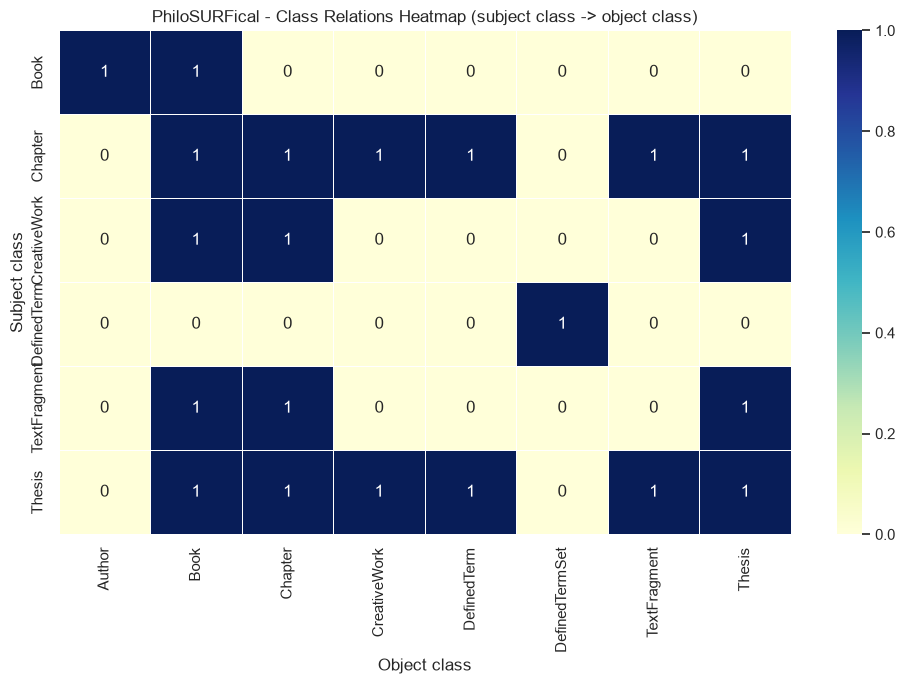

In [11]:
heatmap_data = (
    relations_df.groupby(["subject_class", "object_class"])
    .size().unstack(fill_value=0)
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt="d", 
    cmap="YlGnBu", 
    linewidths=0.5)

plt.title("PhiloSURFical - Class Relations Heatmap (subject class -> object class)")
plt.xlabel("Object class")
plt.ylabel("Subject class")
plt.tight_layout()
plt.show()

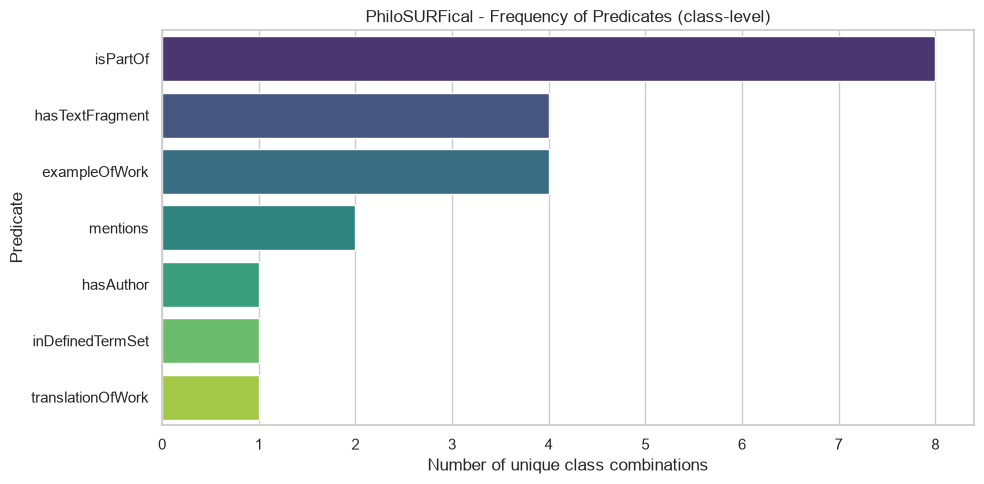

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=predicate_counts, 
    x="count", 
    y="predicate", 
    hue="predicate", 
    legend=False, 
    palette="viridis")

plt.title("PhiloSURFical - Frequency of Predicates (class-level)")
plt.xlabel("Number of unique class combinations")
plt.ylabel("Predicate")
plt.tight_layout()
plt.show()

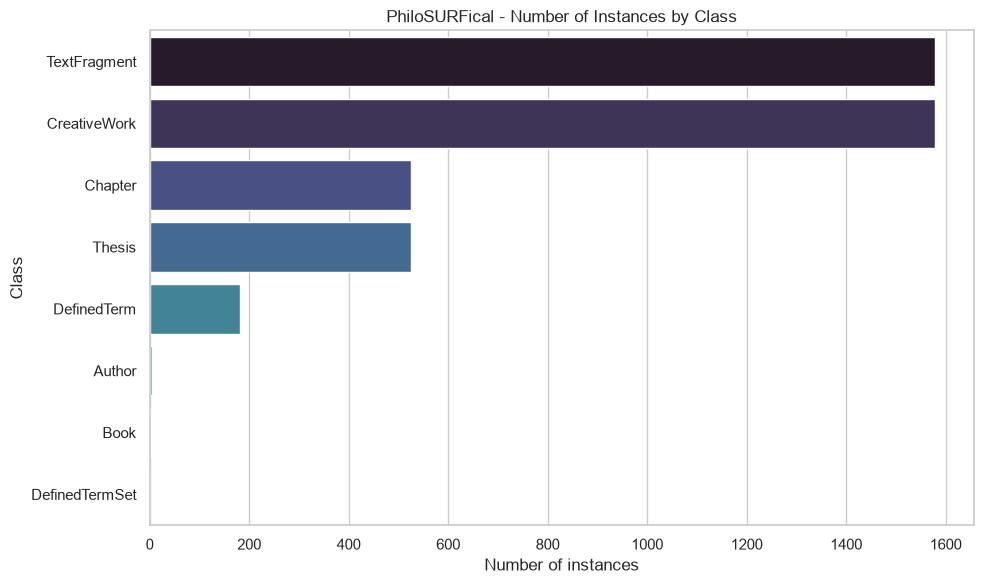

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=class_counts, 
    x="instance_count", 
    y="class", hue="class", 
   legend=False, 
    palette="mako")

plt.title("PhiloSURFical - Number of Instances by Class")
plt.xlabel("Number of instances")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

In [14]:
related_resources = set()

for subject, predicate, obj in unique_triples:
    if isinstance(subject, URIRef):
        related_resources.add(subject)

    if isinstance(obj, URIRef):
        related_resources.add(obj)

print(f"Related resources: {len(related_resources):,}")

type_counter = Counter()
for resource in related_resources:
    for resource_type in get_resource_types(resource):
        if resource_type in classes:
            type_counter[get_local_name(resource_type)] += 1

type_df = pd.DataFrame(
    type_counter.items(), columns=["class", "count"]
).sort_values("count", ascending=False).reset_index(drop=True)
display(type_df)

Related resources: 2,294


,class,count
0,TextFragment,1578
1,CreativeWork,1578
2,Thesis,526
3,Chapter,526
4,DefinedTerm,182
5,Author,4
6,Book,3
7,DefinedTermSet,1


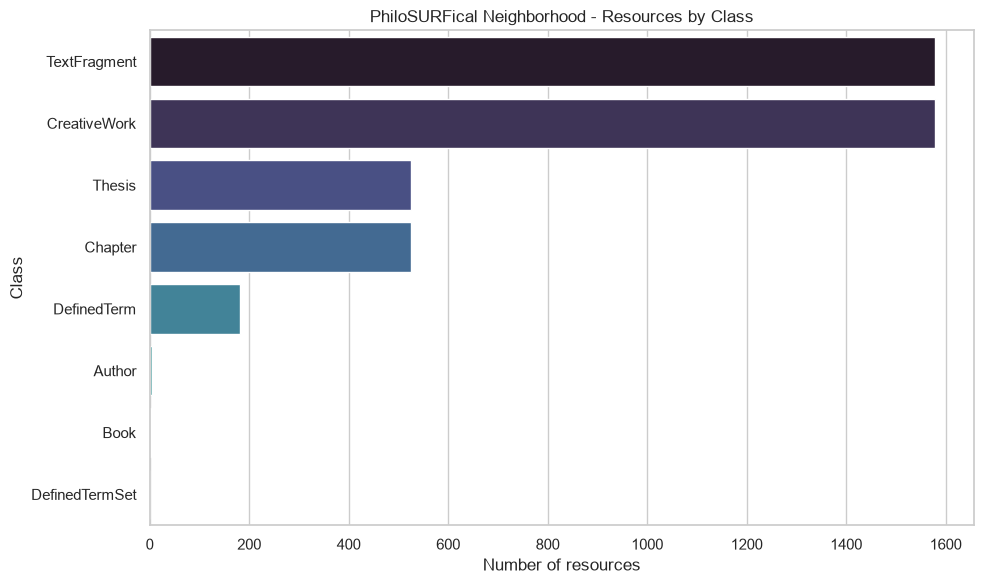

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=type_df, 
    x="count", 
    y="class", 
    hue="class", 
    legend=False, 
    palette="mako")

plt.title("PhiloSURFical Neighborhood - Resources by Class")
plt.xlabel("Number of resources")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

## Summary

In [16]:
print(f"OWL classes: {len(classes)}")
print(f"Starting resources: {len(start_resources):,}")
print(f"Extracted triples: {len(unique_triples):,}")
print(f"Class-level relations: {len(relations_df)}")
print(f"Related resources: {len(related_resources):,}")

OWL classes: 8
Starting resources: 2,294
Extracted triples: 11,124
Class-level relations: 21
Related resources: 2,294
